# 02 · Investigating unusual tracking values

This notebook follows [Notebook 01](01_understand_shot_logs.ipynb) and looks at three shot-level tracking issues.

1. Exactly 0 ft to the closest defender
2. Negative touch time
3. Blank shot clock

The analysis uses 101,997 attempts from games before February 1, 2015. February and later games remain reserved for final testing. Observed make rates describe the shots in each group and can differ with shooter, shot mix, and situation.

In [1]:
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

raw = pd.read_csv(root / "data" / "raw" / "shot_logs.csv", dtype={"GAME_ID": "string"})
game_date = pd.to_datetime(raw["MATCHUP"].str.split(" - ", n=1).str[0], format="%b %d, %Y")
final_holdout_start = pd.Timestamp("2015-02-01")
shots = raw.loc[game_date.lt(final_holdout_start)].copy()
shots["GAME_DATE"] = game_date.loc[shots.index]
clock = shots["GAME_CLOCK"].str.split(":", expand=True).astype(int)
shots["PERIOD_SECONDS"] = clock[0] * 60 + clock[1]
shots["ZERO_DEFENDER"] = shots["CLOSE_DEF_DIST"].eq(0)
shots["NEGATIVE_TOUCH"] = shots["TOUCH_TIME"].lt(0)
shots["MISSING_SHOT_CLOCK"] = shots["SHOT_CLOCK"].isna()

assert shots["GAME_DATE"].max() < final_holdout_start
print(f"{len(shots):,} attempts across {shots['GAME_ID'].nunique():,} games before February 1.")

101,997 attempts across 710 games before February 1.


## 1. How common are the issues?

Look at the counts and their overlaps before considering row removal. Each pairwise overlap includes rows that may also have the third flag. Rates are given alongside counts so changes in sample size are visible.

,attempts,share_pct
Zero defender distance,835,0.82
Negative touch time,258,0.25
Missing shot clock,4626,4.54


,Zero defender distance,Negative touch time,Missing shot clock
Zero defender distance,835,6,47
Negative touch time,6,258,12
Missing shot clock,47,12,4626


Attempts with at least one flag: 5,655


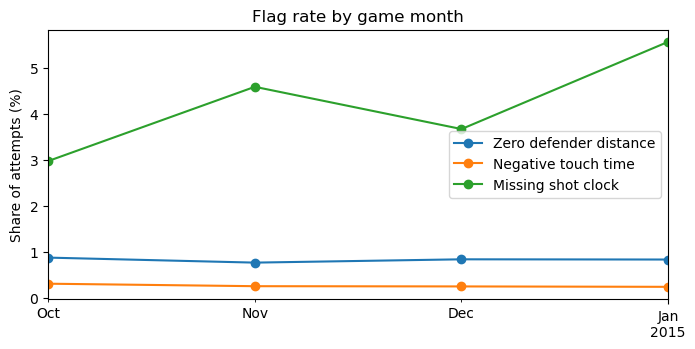

In [2]:
flag_names = {
    "ZERO_DEFENDER": "Zero defender distance",
    "NEGATIVE_TOUCH": "Negative touch time",
    "MISSING_SHOT_CLOCK": "Missing shot clock",
}
flags = shots[list(flag_names)].rename(columns=flag_names)
display(pd.DataFrame({"attempts": flags.sum(), "share_pct": flags.mean().mul(100).round(2)}))
display(flags.astype(int).T @ flags.astype(int))
print(f"Attempts with at least one flag: {flags.any(axis=1).sum():,}")

monthly = (
    shots.assign(month=shots["GAME_DATE"].dt.to_period("M"))
    .groupby("month", observed=True)[list(flag_names)]
    .mean().mul(100).rename(columns=flag_names)
)
ax = monthly.plot(marker="o", figsize=(8, 3.5), title="Flag rate by game month")
ax.set(ylabel="Share of attempts (%)", xlabel="")
display(ax.figure)
plt.close(ax.figure)

## 2. Exactly zero feet to the closest defender

An exact zero could reflect coordinate overlap, rounding near contact, or a tracking convention. Compare the frequency with adjacent positive readings, then check whether zeros appear across different games and shot contexts. The shot distance below is distance to the basket. It provides context for the attempt and is a separate measurement from defender distance.

,attempts,make_pct
CLOSE_DEF_DIST,,
0.0,835,42.5
0.1,468,43.8
0.2,402,46.0
0.3,423,49.9
0.4,499,45.9
0.5,511,44.8
0.6,586,47.6
0.7,644,46.4
0.8,717,43.2


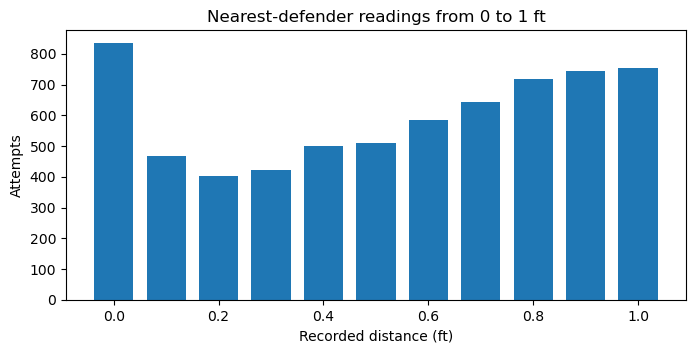

In [3]:
near = shots.loc[shots["CLOSE_DEF_DIST"].between(0, 1)].copy()
fine = near.groupby("CLOSE_DEF_DIST")["FGM"].agg(attempts="size", make_rate="mean")
fine["make_pct"] = fine.pop("make_rate").mul(100).round(1)
display(fine)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(fine.index, fine["attempts"], width=0.075)
ax.set(title="Nearest-defender readings from 0 to 1 ft", xlabel="Recorded distance (ft)", ylabel="Attempts")
display(fig)
plt.close(fig)

In [4]:
near["reading"] = np.where(near["ZERO_DEFENDER"], "Exactly 0 ft", "0.1–1.0 ft")
near["shot_distance_band"] = pd.cut(near["SHOT_DIST"], [0, 4, 10, 22, np.inf], right=False)
near_context = near.groupby(["PTS_TYPE", "shot_distance_band", "reading"], observed=True)["FGM"].agg(
    attempts="size", make_rate="mean",
)
near_context["make_pct"] = near_context.pop("make_rate").mul(100).round(1)
display(near_context)

for key in ["player_name", "CLOSEST_DEFENDER", "GAME_ID"]:
    by_key = shots.groupby(key)["ZERO_DEFENDER"].agg(attempts="size", zeros="sum")
    by_key["zero_share_pct"] = by_key["zeros"].div(by_key["attempts"]).mul(100).round(1)
    print(f"Highest zero counts by {key}")
    display(by_key.nlargest(5, "zeros"))

attempts  make_pct
PTS_TYPE shot_distance_band reading                         
2        [0.0, 4.0)         0.1–1.0 ft        2880      51.3
                            Exactly 0 ft       466      45.1
         [4.0, 10.0)        0.1–1.0 ft        2433      41.3
                            Exactly 0 ft       311      40.8
         [10.0, 22.0)       0.1–1.0 ft         319      33.2
                            Exactly 0 ft        33      36.4
         [22.0, inf)        0.1–1.0 ft          12      25.0
3        [10.0, 22.0)       0.1–1.0 ft          27      22.2
                            Exactly 0 ft         2       0.0
         [22.0, inf)        0.1–1.0 ft          77      20.8
                            Exactly 0 ft        23      26.1

Highest zero counts by player_name


,attempts,zeros,zero_share_pct
player_name,,,
chris kaman,389,14,3.6
greg monroe,551,13,2.4
joakim noah,264,13,4.9
kyrie irving,761,12,1.6
pau gasol,671,12,1.8


Highest zero counts by CLOSEST_DEFENDER


,attempts,zeros,zero_share_pct
CLOSEST_DEFENDER,,,
"Gibson, Taj",394,15,3.8
"Hibbert, Roy",406,11,2.7
"Gasol, Pau",618,10,1.6
"Hill, Jordan",559,10,1.8
"Dieng, Gorgui",525,9,1.7


Highest zero counts by GAME_ID


,attempts,zeros,zero_share_pct
GAME_ID,,,
21400286,134,8,6.0
21400447,160,8,5.0
21400473,182,8,4.4
21400590,147,8,5.4
21400342,172,7,4.1


There are **835 exact zeros**, compared with **468 readings at 0.1 ft**. The largest single-game count is eight, so the spike cannot be attributed to one game. The outcome differences also vary with shot context. Inside 4 ft, the two-point make rate is **45.1% at zero** and **51.3% at 0.1–1.0 ft**. From 4 to under 10 ft, the two groups differ by only **0.5 percentage points**. Even these comparisons can reflect differences in shooter, shot type, or defender.

**Plausible treatments**

- **Keep zero** as the recorded lower boundary. This preserves the possibility of genuinely very tight coverage and retains the original resolution.
- **Set exact zeros to missing** in a derived column. This treats the distance as uncertain while retaining the shot and its other measurements. It would lose the distance signal for any genuine near-contact shots.
- **Group zeros with nearby readings** for a descriptive chart, for example as a 0–1 ft band. This avoids claiming more precision than the measurements support. An unusual zero code would still be mixed into the band.

**Working choice.** Keep the raw zero. These checks cannot establish which zeros correspond to real near contact.

## 3. Negative touch time

A negative duration is physically implausible. Small negative readings and extreme negatives could have different causes, so inspect their sizes and compare them with dribble counts and observed shot outcomes. These checks can describe patterns without recovering the true duration.

In [5]:
negative = shots.loc[shots["NEGATIVE_TOUCH"]].copy()
negative["touch_band"] = pd.cut(
    negative["TOUCH_TIME"], [-np.inf, -10, -1, -0.5, 0], right=False,
    labels=["Below −10", "−10 to <−1", "−1 to <−0.5", "−0.5 to <0"],
)
display(negative["TOUCH_TIME"].describe().to_frame("negative touch time (s)"))
display(negative.groupby("touch_band", observed=False).agg(
    attempts=("FGM", "size"), mean_dribbles=("DRIBBLES", "mean"),
    median_shot_distance=("SHOT_DIST", "median"), make_rate=("FGM", "mean"),
).round(3))
display(negative.nsmallest(8, "TOUCH_TIME")[[
    "MATCHUP", "player_name", "PERIOD", "GAME_CLOCK", "TOUCH_TIME", "DRIBBLES", "SHOT_CLOCK",
]])

shots["DRIBBLE_BAND"] = pd.cut(
    shots["DRIBBLES"], [-1, 0, 1, 3, np.inf], labels=["0", "1", "2–3", "4+"],
)
dribble_profile = shots.groupby("DRIBBLE_BAND", observed=True)["NEGATIVE_TOUCH"].agg(
    attempts="size", flagged="sum", flag_rate="mean",
)
dribble_profile["flag_share_pct"] = dribble_profile.pop("flag_rate").mul(100).round(2)
display(dribble_profile)

zero_dribble = shots.loc[shots["DRIBBLES"].eq(0)]
touch_state = np.select(
    [zero_dribble["TOUCH_TIME"].lt(0), zero_dribble["TOUCH_TIME"].eq(0)],
    ["Negative", "Exactly zero"], default="Positive",
)
display(zero_dribble.groupby(touch_state).agg(
    attempts=("FGM", "size"),
    median_shot_distance=("SHOT_DIST", "median"),
    make_pct=("FGM", lambda makes: makes.mean() * 100),
).round(2))

,negative touch time (s)
count,258.000000
mean,-2.768992
std,12.074205
min,-163.600000
25%,-2.250000
50%,-0.400000
75%,-0.200000
max,-0.100000


,attempts,mean_dribbles,median_shot_distance,make_rate
touch_band,,,,
Below −10,6,0.0,22.55,0.167
−10 to <−1,88,0.0,3.50,0.193
−1 to <−0.5,22,0.0,2.85,0.273
−0.5 to <0,142,0.0,17.70,0.415


,MATCHUP,player_name,PERIOD,GAME_CLOCK,TOUCH_TIME,DRIBBLES,SHOT_CLOCK
50259,"JAN 09, 2015 - IND vs. BOS",cj miles,2,10:21,-163.6,0,NaN
5574,"JAN 22, 2015 - UTA @ MIL",trevor booker,2,11:23,-100.5,0,15.0
7057,"NOV 07, 2014 - UTA vs. DAL",derrick favors,2,1:33,-14.0,0,24.0
43047,"NOV 05, 2014 - ORL @ PHI",elfrid payton,3,4:53,-13.6,0,24.0
81506,"JAN 02, 2015 - MEM @ LAL",courtney lee,1,8:19,-11.1,0,NaN
35545,"NOV 04, 2014 - TOR vs. OKC",patrick patterson,3,11:21,-10.7,0,16.6
30394,"NOV 22, 2014 - NOP @ UTA",anthony davis,4,1:56,-9.8,0,24.0
87330,"JAN 17, 2015 - DET vs. PHI",kentavious caldwell-pope,3,4:51,-9.4,0,20.5


,attempts,flagged,flag_share_pct
DRIBBLE_BAND,,,
0,50273,258,0.51
1,15462,0,0.00
2–3,17295,0,0.00
4+,18967,0,0.00


,attempts,median_shot_distance,make_pct
Exactly zero,2441,3.10,48.05
Negative,258,7.55,32.17
Positive,47574,19.80,47.55


All **258** negative readings occur on shots with **zero recorded dribbles**. The median negative reading is **−0.4 s**, but six readings are below **−10 s**, including one at **−163.6 s**. No recorded dribbles is compatible with a quick release or a held ball followed by a shot. It cannot establish how long the player held the ball.

**Plausible treatments**

- **Set negative durations to missing** in a derived column. This keeps the shot and prevents the negative magnitude from being treated as a duration.
- **Clamp negatives to zero** only if there is evidence that they represent nearly instantaneous releases. Clamping all negatives would turn even −163.6 s into a precise zero and merge invalid readings with recorded zeros.
- **Investigate timing from another source** if possession and release timestamps become available. Dribble count and game-clock timestamps alone cannot recover touch duration.

**Working choice.** Mark negative durations as missing and retain the recorded values for audit. Leave recorded zero and positive durations as they are.

## 4. Blank shot clock

A blank already loads as missing. Compare blanks with recorded zero and positive values, then look at where blanks occur in the period and whether they cluster by game. A blank late in the quarter can occur when the shot clock is off. Some games also have missing readings throughout, which suggests a separate coverage problem.

,attempts,missing,missing_pct
PERIOD_CLOCK_BAND,,,
0–5 s,2379,2173,91.34
6–24 s,2162,674,31.17
25–60 s,5594,86,1.54
61–180 s,16539,298,1.80
181+ s,75323,1395,1.85


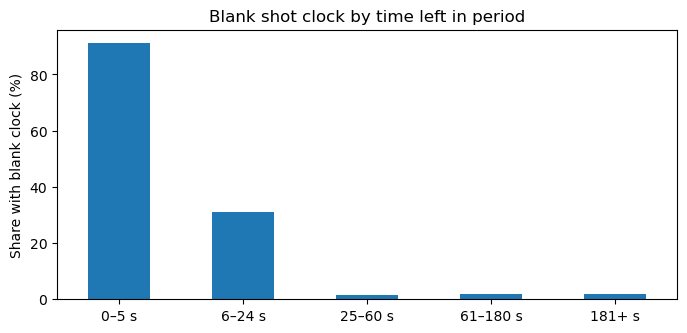

,attempts,make_rate,median_shot_distance,three_point_share
CLOCK_STATE,,,,
Missing,4626,0.366,18.30,0.402
Recorded 0 s,66,0.212,20.65,0.409
Recorded positive,97305,0.458,13.40,0.258


,,attempts,missing,missing_rate
GAME_ID,GAME_DATE,,,
21400339,2014-12-12,179,179,1.000
21400579,2015-01-14,154,154,1.000
21400115,2014-11-12,148,148,1.000
21400616,2015-01-19,148,148,1.000
21400032,2014-11-01,142,142,1.000
21400648,2015-01-23,144,139,0.965
21400084,2014-11-08,137,137,1.000
21400088,2014-11-08,124,124,1.000


In [6]:
shots["PERIOD_CLOCK_BAND"] = pd.cut(
    shots["PERIOD_SECONDS"], [-1, 5, 24, 60, 180, np.inf],
    labels=["0–5 s", "6–24 s", "25–60 s", "61–180 s", "181+ s"],
)
clock_profile = shots.groupby("PERIOD_CLOCK_BAND", observed=True)["MISSING_SHOT_CLOCK"].agg(
    attempts="size", missing="sum", missing_rate="mean",
)
clock_profile["missing_pct"] = clock_profile.pop("missing_rate").mul(100).round(2)
display(clock_profile)
ax = clock_profile["missing_pct"].plot.bar(
    figsize=(8, 3.5), rot=0, title="Blank shot clock by time left in period",
)
ax.set(xlabel="", ylabel="Share with blank clock (%)")
display(ax.figure)
plt.close(ax.figure)

shots["CLOCK_STATE"] = np.select(
    [shots["MISSING_SHOT_CLOCK"], shots["SHOT_CLOCK"].eq(0)],
    ["Missing", "Recorded 0 s"], default="Recorded positive",
)
display(shots.groupby("CLOCK_STATE").agg(
    attempts=("FGM", "size"), make_rate=("FGM", "mean"),
    median_shot_distance=("SHOT_DIST", "median"), three_point_share=("PTS_TYPE", lambda x: x.eq(3).mean()),
).round(3))

by_game = shots.groupby(["GAME_ID", "GAME_DATE"])["MISSING_SHOT_CLOCK"].agg(
    attempts="size", missing="sum", missing_rate="mean",
)
display(by_game.nlargest(8, "missing").round(3))

### Use the period clock for late blanks

The shot clock is blank on **91.3%** of attempts in the final five seconds, compared with **1.5–1.9%** in the bands above 24 seconds. Several games have no recorded clocks in this archive, so late-period timing cannot explain every blank.

**Chosen rule.** For the **2,847** development-set attempts with a blank shot clock and **24 seconds or less** left in the period, use the period clock in seconds as the shot-clock proxy. The cutoff includes the three blanks at exactly 24 seconds. Apply this as the first pass in a derived shot-clock column, preserve every recorded value (including recorded zeros), and leave the **1,779** blanks above 24 seconds for the reconstruction step. The raw CSV stays intact.

The period clock is the deadline when the shot clock is off. Some unresolved possessions could have had an active shot clock that expired sooner, so the fill can overstate how much time the shooter had. A fill of zero when the period clock reads 0:00 represents the recorded period time at the archive's whole-second precision.

In [7]:
blank_clock = shots["MISSING_SHOT_CLOCK"]
late_blank = blank_clock & shots["PERIOD_SECONDS"].le(24)
recorded_clock = shots["SHOT_CLOCK"]
shots["SHOT_CLOCK_CLEAN"] = recorded_clock.mask(late_blank, shots["PERIOD_SECONDS"])
filled_clock = shots["SHOT_CLOCK_CLEAN"]

assert filled_clock.loc[~blank_clock].equals(recorded_clock.loc[~blank_clock])
assert filled_clock.loc[late_blank].eq(shots.loc[late_blank, "PERIOD_SECONDS"]).all()
assert filled_clock.isna().eq(blank_clock & ~late_blank).all()

display(pd.Series({
    "Blank before fill": blank_clock.sum(),
    "Filled from period clock": late_blank.sum(),
    "Of which exactly 24 seconds": (late_blank & shots["PERIOD_SECONDS"].eq(24)).sum(),
    "Blank after period-clock fill": filled_clock.isna().sum(),
    "Recorded values preserved": (~blank_clock).sum(),
}, name="Attempts").to_frame())

,Attempts
Blank before fill,4626
Filled from period clock,2847
Of which exactly 24 seconds,3
Blank after period-clock fill,1779
Recorded values preserved,97371


### What the official play-by-play reconstruction found

The separate [shot-clock reconstruction audit](../docs/shot-clock-reconstruction.md) pulled official NBA play-by-play for **702 games** with missing shot clocks. It matched **4,530 of 4,626** blanks to unique events using the game, shooter, period, shot value, result, and nearby game-clock time. The feed provides the period clock and event sequence. It has no recorded shot-clock reading.

| Audit classification | Blank with 24 s or less left | Blank with more than 24 s left | Total |
| --- | ---: | ---: | ---: |
| Numeric estimate | 18 | 540 | 558 |
| Likely off | 1,150 | 0 | 1,150 |
| Unresolved | 1,679 | 1,239 | 2,918 |
| **Total** | **2,847** | **1,779** | **4,626** |

- **Numeric estimate.** For clearly identified starts, such as a defensive rebound or paired steal, the audit subtracts elapsed game time from 24 seconds. It also uses an opponent's made basket when it falls within the stopped-clock window. On 580 January shots whose recorded values were hidden and then compared, the average absolute error was **1.44 s**. Estimates averaged **1.18 s below** the recorded values.
- **Likely off.** The event sequence supports a new possession with 24 seconds or less remaining. The audit records the inferred state and leaves the numeric estimate blank.
- **Unresolved.** The shot match or preceding sequence was too uncertain for either classification. For example, an offensive rebound may have reset the clock, but the play-by-play may omit whether the ball hit the rim.

### Apply both fills to one column

Start with the recorded shot clock in `SHOT_CLOCK_CLEAN`. Fill the 2,847 eligible late blanks from the period clock first. Then use available numeric play-by-play estimates between 0 and 24 seconds for any originally blank row. This replaces the period-clock proxy on **18** late shots and fills **540** earlier blanks. All 18 overlapping estimates are below the period time, so the estimate reduces the risk of overstating the time available on those attempts. The final column uses **2,829** period-clock values and **558** estimates, with **1,239** still missing. Every recorded shot clock is preserved.

If the local audit CSV is missing, the notebook shows the period-clock fill alone. To generate the CSV, follow the [reconstruction audit instructions](../docs/shot-clock-reconstruction.md) and rerun this section.

In [8]:
audit_path = root / "data" / "processed" / "shot-clock-review" / "missing-shot-clocks.csv"
reconstructed = pd.Series(np.nan, index=shots.index)
if audit_path.is_file():
    audit = pd.read_csv(audit_path, dtype={"game_id": "string"})
    audit = audit.loc[audit["status"].eq("estimated")].copy()
    audit["game_id"] = audit["game_id"].str.zfill(10)
    estimates = audit.set_index(["game_id", "player_id", "shot_number"], verify_integrity=True)
    shot_keys = pd.MultiIndex.from_arrays([
        shots["GAME_ID"].str.zfill(10), shots["player_id"], shots["SHOT_NUMBER"],
    ])
    reconstructed = pd.Series(estimates["estimated_shot_clock"].reindex(shot_keys).to_numpy(), index=shots.index)
else:
    print("Local reconstruction audit not found. Showing the period-clock fill only.")

use_reconstruction = blank_clock & reconstructed.between(0, 24)
use_period_clock = late_blank & ~use_reconstruction
shots.loc[use_reconstruction, "SHOT_CLOCK_CLEAN"] = reconstructed.loc[use_reconstruction]
clean_clock = shots["SHOT_CLOCK_CLEAN"]

assert clean_clock.loc[~blank_clock].equals(recorded_clock.loc[~blank_clock])
assert clean_clock.loc[use_period_clock].eq(shots.loc[use_period_clock, "PERIOD_SECONDS"]).all()
assert clean_clock.loc[use_reconstruction].equals(reconstructed.loc[use_reconstruction])
assert clean_clock.isna().eq(blank_clock & ~late_blank & ~use_reconstruction).all()

display(pd.Series({
    "Recorded values preserved": (~blank_clock).sum(),
    "Filled from period clock": use_period_clock.sum(),
    "Filled from play-by-play estimate": use_reconstruction.sum(),
    "Of which replaced a period-clock proxy": (late_blank & use_reconstruction).sum(),
    "Still missing": clean_clock.isna().sum(),
}, name="Attempts").to_frame())

,Attempts
Recorded values preserved,97371
Filled from period clock,2829
Filled from play-by-play estimate,558
Of which replaced a period-clock proxy,18
Still missing,1239


## 5. Data treatment summary

| Issue | Working treatment | Remaining uncertainty |
| --- | --- | --- |
| Exactly 0 ft to the closest defender | Preserve the recorded zero. Consider missing as an alternative. | The meaning of an exact zero is unverified. |
| Negative touch time | Treat negative values as missing in a derived version. | True duration is unknown, even with zero recorded dribbles. |
| Blank shot clock | Use valid numeric estimates for originally blank rows. Use period seconds for other late blanks. | The period-clock proxy can overstate time left, and reconstruction estimates have measured error. |